In [2]:
import numpy as np


import mplscience
import seaborn as sns

mplscience.available_styles()
mplscience.set_style()

import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.optimize import brentq
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
import warnings, time, os

['default', 'despine']


In [3]:
# ════════════════════════════════════════════════════════════════
# CONFIGURATION — edit these as needed
# ════════════════════════════════════════════════════════════════
OUTPUT_DIR = "./figures"           # where to save plots
M = 30                             # number of quantile levels
N_INIT = 5                         # initial random observations
N_ITER = 5                        # acquisition iterations
N_REPEATS = 50                    # random restarts for averaging
N_TEST = 60                        # test grid resolution
N_DENSE = 200                      # grid for lengthscale pre-fitting
N_CANDIDATES = 100                 # acquisition candidate grid

# Ground truth parameters
A_MEAN = 1.0                       # mean amplitude
C_SEP = 1.0                        # mode separation slope
SIGMA = 0.2                       # component std

os.makedirs(OUTPUT_DIR, exist_ok=True)

In [4]:
# ════════════════════════════════════════════════════════════════
# GROUND TRUTH
# ════════════════════════════════════════════════════════════════

def m_func(x):
    """Conditional mean: smooth sinusoid."""
    return A_MEAN * x

def d_func(x):
    """Half-distance between modes: grows linearly."""
    # return C_SEP * x**0.5
    return C_SEP * np.exp(-20 * (x - 0.5)**2)

def sigma_func(x):
    """Conditional std: linear function of x."""
    return SIGMA * (1 + x)**2

def mixture_cdf(y, x):
    """CDF of the symmetric two-component Gaussian mixture at (y, x)."""
    dd = d_func(x)
    if dd < 1e-6:
        return norm.cdf(y, m_func(x), sigma_func(x))
    return 0.5 * norm.cdf(y, m_func(x) - dd, sigma_func(x)) + \
           0.5 * norm.cdf(y, m_func(x) + dd, sigma_func(x))

def quantile_function(tau, x):
    """Inverse CDF F_x^{-1}(τ) via root-finding."""
    if tau <= 1e-8: return -5.0
    if tau >= 1 - 1e-8: return 5.0
    return brentq(lambda y: mixture_cdf(y, x) - tau, -5, 5)

def observe_quantiles(x_val, tau_grid):
    """Observe the full quantile function at input x_val."""
    return np.array([quantile_function(tau, x_val) for tau in tau_grid])

In [5]:
print("=" * 60)
print("STEP 1: Precomputing ground truth")
print("=" * 60)

tau_grid = np.linspace(0.03, 0.97, M)
dtau = tau_grid[1] - tau_grid[0]

x_test = np.linspace(0.01, 0.99, N_TEST)
x_dense = np.linspace(0.01, 0.99, N_DENSE)

# Ground truth quantile surface on test grid
Q_true_test = np.zeros((N_TEST, M))
for i, x in enumerate(x_test):
    for j, tau in enumerate(tau_grid):
        Q_true_test[i, j] = quantile_function(tau, x)
m_true_test = np.mean(Q_true_test, axis=1)  # mean ≈ ∫ F^{-1}(τ) dτ

# Ground truth on dense grid (for lengthscale fitting)
Q_dense = np.zeros((N_DENSE, M))
for i, x in enumerate(x_dense):
    for j, tau in enumerate(tau_grid):
        Q_dense[i, j] = quantile_function(tau, x)
m_dense = np.mean(Q_dense, axis=1)

print(f"  Test grid: {N_TEST} points, Dense grid: {N_DENSE} points, M={M} quantile levels")

STEP 1: Precomputing ground truth
  Test grid: 60 points, Dense grid: 200 points, M=30 quantile levels


In [6]:
# ════════════════════════════════════════════════════════════════
# STEP 2: PRE-FIT PER-QUANTILE GP LENGTHSCALES
# ════════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("STEP 2: Fitting per-quantile GP lengthscales on ground truth")
print("=" * 60)

ls_per_tau = np.zeros(M)
amp_per_tau = np.zeros(M)
X_fit = x_dense.reshape(-1, 1)

for j in range(M):
    kernel = ConstantKernel(1.0, (0.01, 100)) * RBF(0.15, (0.01, 2.0)) 
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=5, alpha=1e-7)
    gp.fit(X_fit, Q_dense[:, j])
    k = gp.kernel_
    amp_per_tau[j] = k.k1.constant_value
    ls_per_tau[j] = k.k2.length_scale
    print(f"  τ={tau_grid[j]:.2f}: lengthscale={ls_per_tau[j]:.4f}, amplitude={amp_per_tau[j]:.3f}")

# Mean GP
kernel_m = ConstantKernel(1.0, (0.01, 100)) * RBF(0.15, (0.01, 2.0)) 
gp_m_fit = GaussianProcessRegressor(kernel=kernel_m, n_restarts_optimizer=5, alpha=1e-7)
gp_m_fit.fit(X_fit, m_dense)
k_m = gp_m_fit.kernel_
ls_mean = k_m.k2.length_scale
amp_mean = k_m.k1.constant_value

print(f"\n  Mean GP:  lengthscale={ls_mean:.4f}, amplitude={amp_mean:.4f}")
print(f"  Quantile: min_ls={ls_per_tau.min():.4f}, max_ls={ls_per_tau.max():.4f}, "
      f"median_ls={np.median(ls_per_tau):.4f}")
print(f"  Ratio (mean / min quantile): {ls_mean / ls_per_tau.min():.1f}x")



STEP 2: Fitting per-quantile GP lengthscales on ground truth
  τ=0.03: lengthscale=0.1240, amplitude=0.178
  τ=0.06: lengthscale=0.1165, amplitude=0.105
  τ=0.09: lengthscale=0.1115, amplitude=0.075
  τ=0.13: lengthscale=0.1077, amplitude=0.058
  τ=0.16: lengthscale=0.1045, amplitude=0.049
  τ=0.19: lengthscale=0.1020, amplitude=0.044
  τ=0.22: lengthscale=0.1011, amplitude=0.043
  τ=0.26: lengthscale=0.1045, amplitude=0.047


/Users/romainlopez/miniforge3/lib/python3.12/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 14 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


  τ=0.29: lengthscale=0.1047, amplitude=0.052
  τ=0.32: lengthscale=0.1024, amplitude=0.058
  τ=0.35: lengthscale=0.0983, amplitude=0.068
  τ=0.39: lengthscale=0.0943, amplitude=0.076
  τ=0.42: lengthscale=0.0912, amplitude=0.083
  τ=0.45: lengthscale=0.1023, amplitude=0.110
  τ=0.48: lengthscale=0.1248, amplitude=0.155
  τ=0.52: lengthscale=0.1264, amplitude=0.182
  τ=0.55: lengthscale=0.1053, amplitude=0.214
  τ=0.58: lengthscale=0.0942, amplitude=0.239
  τ=0.61: lengthscale=0.0995, amplitude=0.275
  τ=0.65: lengthscale=0.1043, amplitude=0.319
  τ=0.68: lengthscale=0.1089, amplitude=0.374
  τ=0.71: lengthscale=0.1133, amplitude=0.444
  τ=0.74: lengthscale=0.1174, amplitude=0.497
  τ=0.78: lengthscale=0.1226, amplitude=0.517
  τ=0.81: lengthscale=0.1259, amplitude=0.564


/Users/romainlopez/miniforge3/lib/python3.12/site-packages/sklearn/gaussian_process/_gpr.py:670: ConvergenceWarning: lbfgs failed to converge after 13 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


  τ=0.84: lengthscale=0.1201, amplitude=0.605
  τ=0.87: lengthscale=0.1205, amplitude=0.683
  τ=0.91: lengthscale=0.1226, amplitude=0.793
  τ=0.94: lengthscale=0.1259, amplitude=0.953
  τ=0.97: lengthscale=0.1324, amplitude=1.267

  Mean GP:  lengthscale=2.0000, amplitude=2.1464
  Quantile: min_ls=0.0912, max_ls=0.1324, median_ls=0.1083
  Ratio (mean / min quantile): 21.9x


/Users/romainlopez/miniforge3/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


In [7]:

# ════════════════════════════════════════════════════════════════
# STEP 3: GP FACTORIES (fixed hyperparameters for speed)
# ════════════════════════════════════════════════════════════════

def make_quantile_gp(j):
    """GP for quantile level j with pre-fitted lengthscale."""
    kernel = ConstantKernel(amp_per_tau[j], constant_value_bounds='fixed') * \
             RBF(ls_per_tau[j], length_scale_bounds='fixed') 
    return GaussianProcessRegressor(kernel=kernel, alpha=1e-6)

def make_mean_gp():
    """GP for the mean function with pre-fitted lengthscale."""
    kernel = ConstantKernel(amp_mean, constant_value_bounds='fixed') * \
             RBF(ls_mean, length_scale_bounds='fixed') 
    return GaussianProcessRegressor(kernel=kernel, alpha=1e-6)


# ════════════════════════════════════════════════════════════════
# STEP 4: EVALUATION + ACQUISITION (combined for efficiency)
# ════════════════════════════════════════════════════════════════

def fit_and_score(X_train, Q_train, x_candidates):
    """
    Fit M quantile GPs + 1 mean GP.
    Returns:
        w2sq:         W_2^2 test error (full distributional)
        mean_mse:     MSE of mean prediction
        shape_error:  W_2^2 minus mean contribution (Eq. 11 shape term)
        var_quantile: acquisition scores for Quantile-AL  [n_candidates]
        var_mean:     acquisition scores for Mean-AL       [n_candidates]
    """
    X_tr = X_train.reshape(-1, 1)
    X_te = x_test.reshape(-1, 1)
    X_cand = x_candidates.reshape(-1, 1)

    Q_pred = np.zeros((N_TEST, M))
    var_cand_per_tau = np.zeros((len(x_candidates), M))

    for j in range(M):
        gp = make_quantile_gp(j)
        gp.fit(X_tr, Q_train[:, j])
        Q_pred[:, j] = gp.predict(X_te)
        _, std_c = gp.predict(X_cand, return_std=True)
        var_cand_per_tau[:, j] = std_c ** 2

    # Integrated quantile variance (Quantile-AL acquisition)
    var_quantile = np.sum(var_cand_per_tau, axis=1) * dtau

    # W2^2 = ∫ (Q_pred(τ) - Q_true(τ))^2 dτ, averaged over test x
    w2sq = np.mean(np.sum((Q_pred - Q_true_test) ** 2, axis=1) * dtau)

    # Mean prediction and MSE
    m_pred = np.mean(Q_pred, axis=1)
    mean_mse = np.mean((m_pred - m_true_test) ** 2)

    # Eq. 11 decomposition: shape error = W2^2 - mean_contribution
    # mean_contribution = (m_pred - m_true)^2 * (integrated dtau = ~1)
    # More precisely: W2^2 = mean_part + shape_part
    # mean_part = (m_pred - m_true)^2  (constant across τ, integrated gives ×1)
    # shape_part = ∫ (g_pred(τ) - g_true(τ))^2 dτ  where g = F^{-1} - m
    g_pred = Q_pred - m_pred[:, None]
    g_true = Q_true_test - m_true_test[:, None]
    shape_error = np.mean(np.sum((g_pred - g_true) ** 2, axis=1) * dtau)

    # Mean GP (Mean-AL acquisition)
    m_train = np.mean(Q_train, axis=1)
    gp_m = make_mean_gp()
    gp_m.fit(X_tr, m_train)
    _, std_m = gp_m.predict(X_cand, return_std=True)
    var_mean = std_m ** 2

    return w2sq, mean_mse, shape_error, var_quantile, var_mean

In [8]:
# ════════════════════════════════════════════════════════════════
# STEP 5: ACTIVE LEARNING LOOP
# ════════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("STEP 5: Running active learning loop")
print("=" * 60)

x_candidates = np.linspace(0.005, 0.995, N_CANDIDATES)

strategies = ['random', 'mean', 'quantile_indep']
results = {s: {
    'w2sq': np.zeros((N_REPEATS, N_ITER + 1)),
    'mean_mse': np.zeros((N_REPEATS, N_ITER + 1)),
    'shape_error': np.zeros((N_REPEATS, N_ITER + 1)),
    'all_points': []
} for s in strategies}

t0 = time.time()
for rep in range(N_REPEATS):
    elapsed = time.time() - t0
    print(f"  Repeat {rep + 1}/{N_REPEATS} ({elapsed:.0f}s elapsed)")

    rng = np.random.RandomState(rep * 77 + 13)
    
    # Force points at the absolute boundaries
    X_edges = np.array([0.0, 1.0])

    # Randomly sample the remaining initial budget in the interior
    if N_INIT > 2:
        X_interior = rng.uniform(0.1, 0.9, N_INIT - 2)
        X_init = np.concatenate([X_edges, X_interior])
    else:
        X_init = X_edges

    # Optional: sort them just to keep things neat
    X_init = np.sort(X_init)

    Q_init = np.array([observe_quantiles(x, tau_grid) for x in X_init])

    state = {s: {'X': X_init.copy(), 'Q': Q_init.copy()} for s in strategies}

    for step in range(N_ITER + 1):
        for s in strategies:
            X_tr, Q_tr = state[s]['X'], state[s]['Q']
            w2sq, mean_mse, shape_err, var_q, var_m = fit_and_score(
                X_tr, Q_tr, x_candidates
            )
            results[s]['w2sq'][rep, step] = w2sq
            results[s]['mean_mse'][rep, step] = mean_mse
            results[s]['shape_error'][rep, step] = shape_err

            if step < N_ITER:
                if s == 'random':
                    x_new = rng.uniform(0, 1)
                elif s == 'mean':
                    x_new = x_candidates[np.argmax(var_m)]
                elif s == 'quantile_indep':
                    x_new = x_candidates[np.argmax(var_q)]

                state[s]['X'] = np.append(X_tr, x_new)
                state[s]['Q'] = np.vstack([Q_tr, observe_quantiles(x_new, tau_grid)])

    for s in strategies:
        results[s]['all_points'].append(state[s]['X'].copy())

print(f"\n  Total time: {time.time() - t0:.0f}s")


STEP 5: Running active learning loop
  Repeat 1/50 (0s elapsed)
  Repeat 2/50 (0s elapsed)
  Repeat 3/50 (1s elapsed)
  Repeat 4/50 (1s elapsed)
  Repeat 5/50 (2s elapsed)
  Repeat 6/50 (2s elapsed)
  Repeat 7/50 (3s elapsed)
  Repeat 8/50 (3s elapsed)
  Repeat 9/50 (3s elapsed)
  Repeat 10/50 (4s elapsed)
  Repeat 11/50 (4s elapsed)
  Repeat 12/50 (5s elapsed)
  Repeat 13/50 (5s elapsed)
  Repeat 14/50 (6s elapsed)
  Repeat 15/50 (6s elapsed)
  Repeat 16/50 (7s elapsed)
  Repeat 17/50 (7s elapsed)
  Repeat 18/50 (7s elapsed)
  Repeat 19/50 (8s elapsed)
  Repeat 20/50 (8s elapsed)
  Repeat 21/50 (9s elapsed)
  Repeat 22/50 (9s elapsed)
  Repeat 23/50 (10s elapsed)
  Repeat 24/50 (10s elapsed)
  Repeat 25/50 (10s elapsed)
  Repeat 26/50 (11s elapsed)
  Repeat 27/50 (11s elapsed)
  Repeat 28/50 (12s elapsed)
  Repeat 29/50 (12s elapsed)
  Repeat 30/50 (13s elapsed)
  Repeat 31/50 (13s elapsed)
  Repeat 32/50 (13s elapsed)
  Repeat 33/50 (14s elapsed)
  Repeat 34/50 (14s elapsed)
  Repea

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


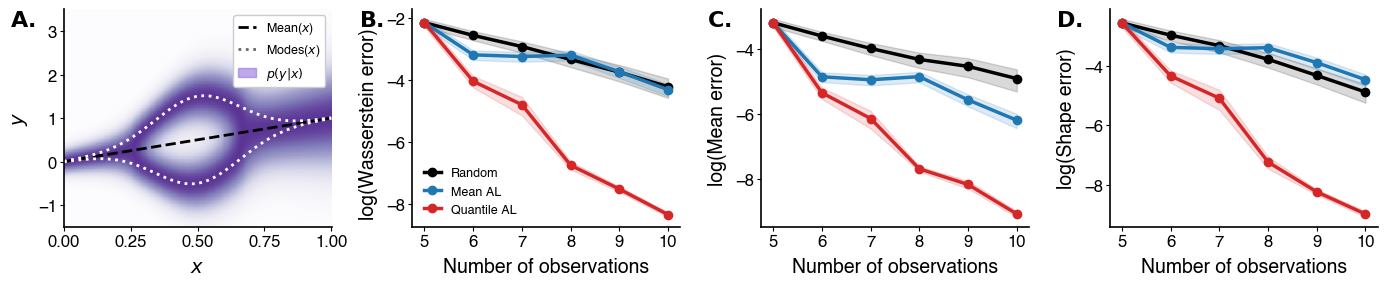

In [19]:
strategies = ['random', 'mean', 'quantile_indep']
colors = {'random': 'black', 'mean': 'C0', 'quantile_indep': 'C3'}
labels = {'random': 'Random', 'mean': 'Mean AL', 'quantile_indep': 'Quantile AL'}
steps = np.arange(N_INIT, N_INIT + N_ITER + 1)

# ── Density field ───────────────────────────────────────────────
 
x_viz = np.linspace(0, 1, 500)
y_viz = np.linspace(-1.5, 3.5, 500)
 
mm = m_func(x_viz)[None, :]
dd = d_func(x_viz)[None, :]
ss = sigma_func(x_viz)[None, :]
yy = y_viz[:, None]
 
density = (0.5 * norm.pdf(yy, mm - dd, ss)
         + 0.5 * norm.pdf(yy, mm + dd, ss))

# Normalize the density so the maximum value at every x is exactly 1.0
density_normalized = density / np.max(density, axis=0)
 
# ── Figure: 4 horizontal panels ────────────────────────────────
 
fig, (ax_a, ax_b, ax_c, ax_d) = plt.subplots(1, 4, figsize=(14, 3))
 
# (a) Ground truth density
mesh = ax_a.pcolormesh(x_viz, y_viz, density_normalized, cmap='Purples', shading='auto',
                rasterized=True, vmin=0, vmax=1.2)
# plot line in back with ":" dashes to make them more visible on top of the colormap
ax_a.plot(x_viz, m_func(x_viz), 'black', linestyle='--', lw=2, label=r'Mean($x$)')
ax_a.plot(x_viz, m_func(x_viz) - d_func(x_viz), 'w:', lw=2, label=r'Modes($x$)')
ax_a.plot(x_viz, m_func(x_viz) + d_func(x_viz), 'w:', lw=2)
ax_a.set(xlabel=r'$x$', ylabel=r'$y$')

# 1. Grab the automatic handles and labels you just created
handles, legend_labels = ax_a.get_legend_handles_labels()


import matplotlib.patches as mpatches
# 2. Create a custom "purple box" for the density
density_patch = mpatches.Patch(color='mediumpurple', alpha=0.6, label='Density')

# 3. Add the box to your lists
handles.append(density_patch)
legend_labels.append(r'$p(y|x)$')

# 4. Create the legend using your custom lists
leg = ax_a.legend(handles=handles, labels=legend_labels, fontsize=9, 
                  frameon=True, facecolor='white', framealpha=1, loc='upper right')

# 5. Fix the Modes line (Index 1) so it's visible against the white background
leg.get_lines()[1].set_color('dimgray')

# ax_a.legend(fontsize=9, frameon=True, facecolor='white', framealpha=1)

 
# (b) W2^2 test error (total)
for s in strategies:
    mu = np.mean(results[s]['w2sq'], axis=0)
    se = np.std(results[s]['w2sq'], axis=0) / np.sqrt(N_REPEATS)
    ax_b.plot(steps, np.log(mu), color=colors[s], lw=2.5, label=labels[s], marker='o')
    ax_b.fill_between(steps, np.log(mu - se), np.log(mu + se), color=colors[s], alpha=0.15)
ax_b.set(xlabel='Number of observations', ylabel='log(Wasserstein error)  ')
ax_b.set_xticks(steps)
ax_b.legend(fontsize=9)
 
# (c) Mean prediction error
for s in strategies:
    mu = np.mean(results[s]['mean_mse'], axis=0)
    se = np.std(results[s]['mean_mse'], axis=0) / np.sqrt(N_REPEATS)
    ax_c.plot(steps, np.log(mu), color=colors[s], lw=2.5, label=labels[s], marker='o')
    ax_c.fill_between(steps, np.log(mu - se), np.log(mu + se), color=colors[s], alpha=0.15)
ax_c.set(xlabel='Number of observations', ylabel='log(Mean error)')
ax_c.set_xticks(steps)
# ax_c.legend(fontsize=9)
 
# (d) Shape error
for s in strategies:
    mu = np.mean(results[s]['shape_error'], axis=0)
    se = np.std(results[s]['shape_error'], axis=0) / np.sqrt(N_REPEATS)
    ax_d.plot(steps, np.log(mu), color=colors[s], lw=2.5, label=labels[s], marker='o')
    ax_d.fill_between(steps, np.log(mu - se), np.log(mu + se), color=colors[s], alpha=0.15)
ax_d.set(xlabel='Number of observations', ylabel='log(Shape error)')
ax_d.set_xticks(steps)
# ax_d.legend(fontsize=9)

# ════════════════════════════════════════════════════════════════
# Add Panel Labels (A, B, C, D) using ax.text for perfect control
# ════════════════════════════════════════════════════════════════
main_axes = [ax_a, ax_b, ax_c, ax_d]
panel_labels = [r'$\mathbf{A.}$', r'$\mathbf{B.}$', r'$\mathbf{C.}$', r'$\mathbf{D.}$']

for ax, label in zip(main_axes, panel_labels):
    # transform=ax.transAxes makes coordinates relative to the plot box
    # adjust the x=-0.20 or y=1.05 if you need to nudge the letters
    ax.text(-0.20, 0.9, label, transform=ax.transAxes, 
            fontsize=16, va='bottom', ha='left')
 
fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "fig_motivating_example.pdf"), dpi=300)

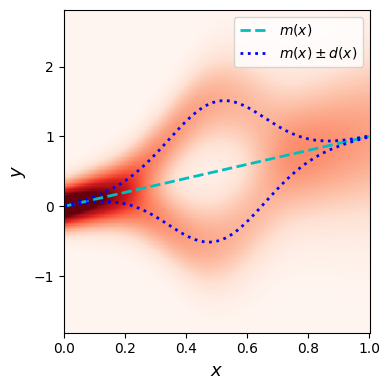

In [ ]:
x_viz = np.linspace(0, 1, 300)
y_viz = np.linspace(-1.8, 2.8, 250)
density = np.zeros((len(y_viz), len(x_viz)))
for i, x in enumerate(x_viz):
    dd = d_func(x)
    if dd < 1e-6:
        density[:, i] = norm.pdf(y_viz, m_func(x), sigma_func(x))
    else:
        density[:, i] = 0.5 * norm.pdf(y_viz, m_func(x) - dd, sigma_func(x)) + \
                         0.5 * norm.pdf(y_viz, m_func(x) + dd, sigma_func(x))

fig, ax = plt.subplots(figsize=(4, 4))
ax.pcolormesh(x_viz, y_viz, density, cmap='Reds', shading='auto', rasterized=True, vmin=0, vmax=1.5)
ax.plot(x_viz, m_func(x_viz), 'c--', lw=2, label=r'$m(x)$')
ax.plot(x_viz, m_func(x_viz) - d_func(x_viz), 'b:', lw=2, alpha=1, label=r'$m(x) \pm d(x)$')
ax.plot(x_viz, m_func(x_viz) + d_func(x_viz), 'b:', lw=2, alpha=1)
ax.set_xlabel(r'$x$', fontsize=13)
ax.set_ylabel(r'$y$', fontsize=13)
# ax.set_title(r'(a) Conditional density $\mu_x$', fontsize=13)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "ground_truth_density.pdf"), dpi=300)

# ── Figure 2: Main AL results (5 panels) ────────────────────────
fig = plt.figure(figsize=(18, 10))

# (a) W2^2
ax = fig.add_subplot(2, 3, 1)
for s in strategies:
    mu = np.mean(results[s]['w2sq'], axis=0)
    se = np.std(results[s]['w2sq'], axis=0) / np.sqrt(N_REPEATS)
    ax.plot(steps, mu, color=colors[s], lw=2.5, label=labels[s])
    ax.fill_between(steps, mu - 2 * se, mu + 2 * se, color=colors[s], alpha=0.15)
ax.set_xlabel('Number of observations', fontsize=12)
ax.set_ylabel(r'$W_2^2$ test error', fontsize=12)
ax.set_title(r'(a) $W_2^2$ test error (total)', fontsize=13)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

# (b) Mean MSE
ax = fig.add_subplot(2, 3, 2)
for s in strategies:
    mu = np.mean(results[s]['mean_mse'], axis=0)
    se = np.std(results[s]['mean_mse'], axis=0) / np.sqrt(N_REPEATS)
    ax.plot(steps, mu, color=colors[s], lw=2.5, label=labels[s])
    ax.fill_between(steps, mu - 2 * se, mu + 2 * se, color=colors[s], alpha=0.15)
ax.set_xlabel('Number of observations', fontsize=12)
ax.set_ylabel('Mean MSE', fontsize=12)
ax.set_title('(b) Mean prediction error', fontsize=13)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

# (c) Shape error (Eq. 11 second term)
ax = fig.add_subplot(2, 3, 3)
for s in strategies:
    mu = np.mean(results[s]['shape_error'], axis=0)
    se = np.std(results[s]['shape_error'], axis=0) / np.sqrt(N_REPEATS)
    ax.plot(steps, mu, color=colors[s], lw=2.5, label=labels[s])
    ax.fill_between(steps, mu - 2 * se, mu + 2 * se, color=colors[s], alpha=0.15)
ax.set_xlabel('Number of observations', fontsize=12)
ax.set_ylabel('Shape error', fontsize=12)
ax.set_title(r'(c) Shape error $\int \|g_{pred} - g_{true}\|^2 d\tau$', fontsize=13)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)


STEP 6: Generating figures
  Saved fig1_ground_truth.png


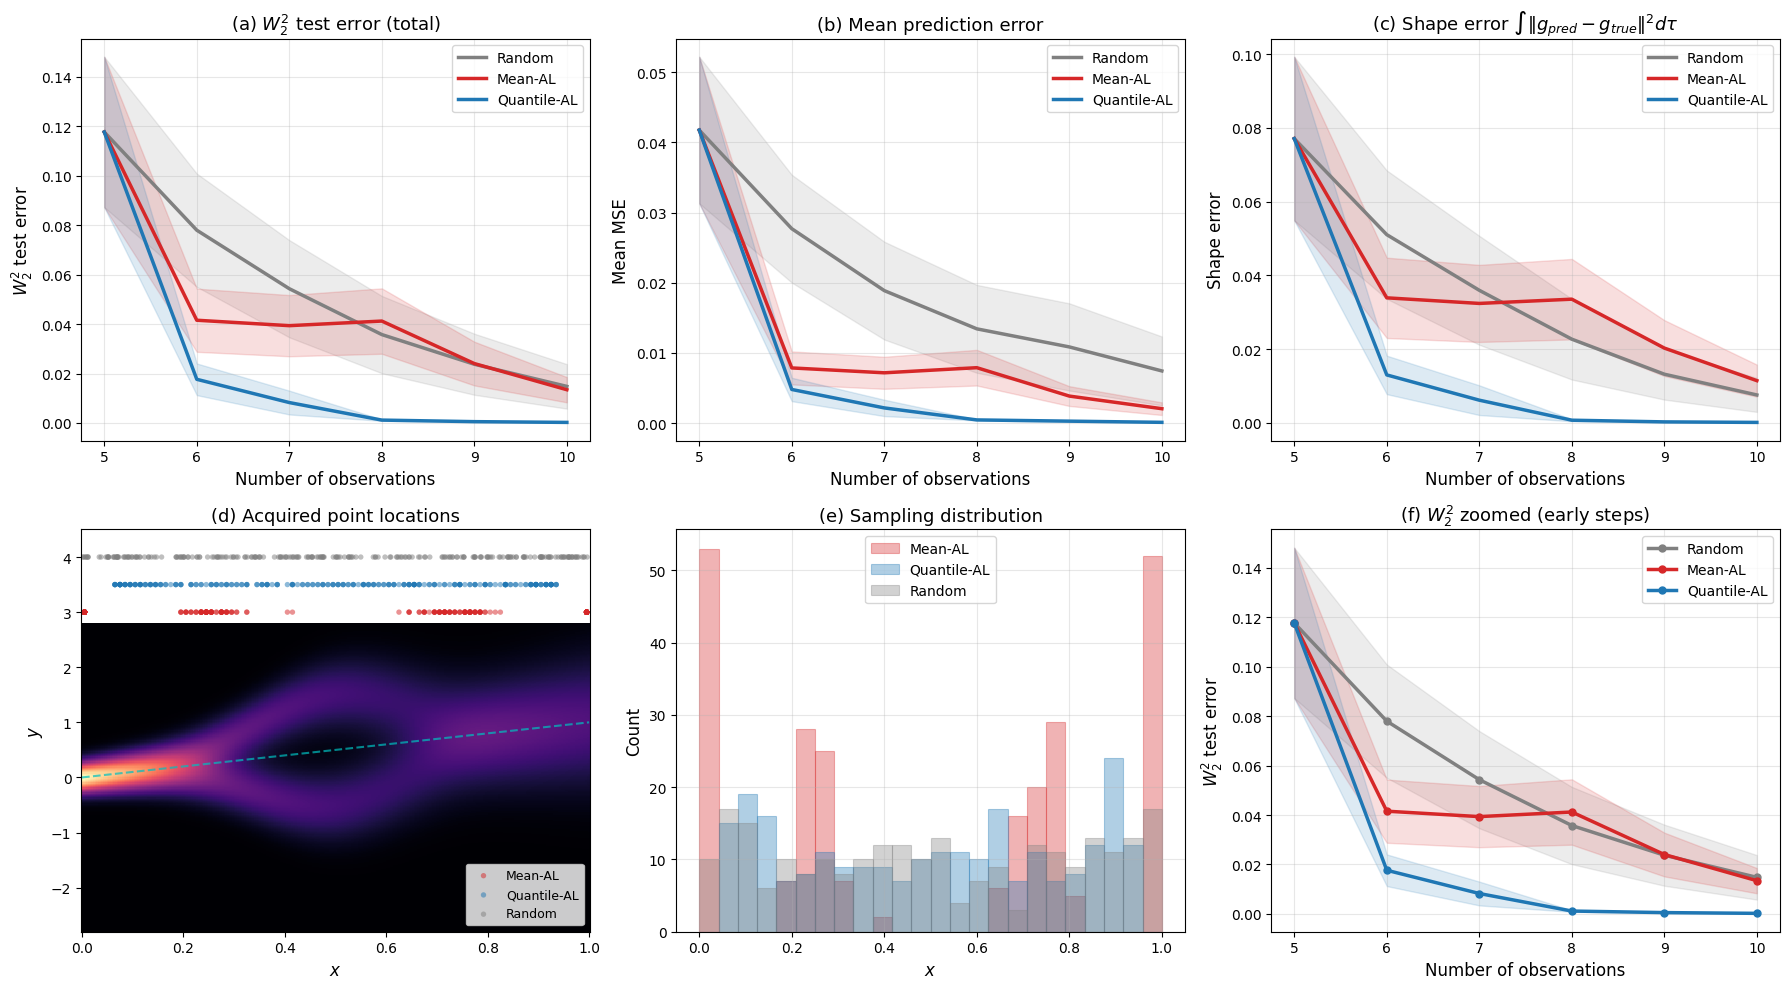

In [72]:

# ════════════════════════════════════════════════════════════════
# STEP 6: FIGURES
# ════════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("STEP 6: Generating figures")
print("=" * 60)

colors = {'random': 'gray', 'mean': 'C3', 'quantile_indep': 'C0'}
labels = {'random': 'Random', 'mean': 'Mean-AL', 'quantile_indep': 'Quantile-AL'}
steps = np.arange(N_INIT, N_INIT + N_ITER + 1)

# ── Figure 1: Ground truth + lengthscale diagnostic ─────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

x_viz = np.linspace(0, 1, 300)
y_viz = np.linspace(-2.8, 2.8, 250)
density = np.zeros((len(y_viz), len(x_viz)))
for i, x in enumerate(x_viz):
    dd = d_func(x)
    if dd < 1e-6:
        density[:, i] = norm.pdf(y_viz, m_func(x), sigma_func(x))
    else:
        density[:, i] = 0.5 * norm.pdf(y_viz, m_func(x) - dd, sigma_func(x)) + \
                         0.5 * norm.pdf(y_viz, m_func(x) + dd, sigma_func(x))

ax = axes[0]
ax.pcolormesh(x_viz, y_viz, density, cmap='magma', shading='auto', rasterized=True)
ax.plot(x_viz, m_func(x_viz), 'c--', lw=2, label=r'$m(x)$')
ax.plot(x_viz, m_func(x_viz) - d_func(x_viz), 'w:', lw=1, alpha=0.5)
ax.plot(x_viz, m_func(x_viz) + d_func(x_viz), 'w:', lw=1, alpha=0.5)
ax.set_xlabel(r'$x$', fontsize=13)
ax.set_ylabel(r'$y$', fontsize=13)
ax.set_title(r'(a) Conditional density $\mu_x$', fontsize=13)
ax.legend(fontsize=10)

ax = axes[1]
ax.plot(tau_grid, ls_per_tau, 'o-', color='C0', lw=2, ms=5, label='Quantile GPs')
ax.axhline(ls_mean, color='C3', ls='--', lw=2.5, label=f'Mean GP ($\\ell$={ls_mean:.2f})')
ax.set_xlabel(r'$\tau$', fontsize=13)
ax.set_ylabel('Lengthscale $\\ell$', fontsize=13)
ax.set_title('(b) Optimal GP lengthscales', fontsize=13)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

ax = axes[2]
slice_xs = [0.05, 0.25, 0.5, 0.75, 0.95]
colors_s = plt.cm.viridis(np.linspace(0.15, 0.85, len(slice_xs)))
for x_val, col in zip(slice_xs, colors_s):
    dd = d_func(x_val)
    if dd < 1e-6:
        pdf_v = norm.pdf(y_viz, m_func(x_val), sigma_func(x_val))
    else:
        pdf_v = 0.5 * norm.pdf(y_viz, m_func(x_val) - dd, sigma_func(x_val)) + \
                0.5 * norm.pdf(y_viz, m_func(x_val) + dd, sigma_func(x_val))
    ax.plot(y_viz, pdf_v, color=col, lw=2, label=f'$x={x_val}$')
ax.set_xlabel(r'$y$', fontsize=13)
ax.set_ylabel('density', fontsize=13)
ax.set_title('(c) Density slices', fontsize=13)
ax.legend(fontsize=9)

plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, 'fig1_ground_truth.png'), dpi=180, bbox_inches='tight')
plt.close()
print("  Saved fig1_ground_truth.png")


# ── Figure 2: Main AL results (5 panels) ────────────────────────
fig = plt.figure(figsize=(18, 10))

# (a) W2^2
ax = fig.add_subplot(2, 3, 1)
for s in strategies:
    mu = np.mean(results[s]['w2sq'], axis=0)
    se = np.std(results[s]['w2sq'], axis=0) / np.sqrt(N_REPEATS)
    ax.plot(steps, mu, color=colors[s], lw=2.5, label=labels[s])
    ax.fill_between(steps, mu - 2 * se, mu + 2 * se, color=colors[s], alpha=0.15)
ax.set_xlabel('Number of observations', fontsize=12)
ax.set_ylabel(r'$W_2^2$ test error', fontsize=12)
ax.set_title(r'(a) $W_2^2$ test error (total)', fontsize=13)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

# (b) Mean MSE
ax = fig.add_subplot(2, 3, 2)
for s in strategies:
    mu = np.mean(results[s]['mean_mse'], axis=0)
    se = np.std(results[s]['mean_mse'], axis=0) / np.sqrt(N_REPEATS)
    ax.plot(steps, mu, color=colors[s], lw=2.5, label=labels[s])
    ax.fill_between(steps, mu - 2 * se, mu + 2 * se, color=colors[s], alpha=0.15)
ax.set_xlabel('Number of observations', fontsize=12)
ax.set_ylabel('Mean MSE', fontsize=12)
ax.set_title('(b) Mean prediction error', fontsize=13)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

# (c) Shape error (Eq. 11 second term)
ax = fig.add_subplot(2, 3, 3)
for s in strategies:
    mu = np.mean(results[s]['shape_error'], axis=0)
    se = np.std(results[s]['shape_error'], axis=0) / np.sqrt(N_REPEATS)
    ax.plot(steps, mu, color=colors[s], lw=2.5, label=labels[s])
    ax.fill_between(steps, mu - 2 * se, mu + 2 * se, color=colors[s], alpha=0.15)
ax.set_xlabel('Number of observations', fontsize=12)
ax.set_ylabel('Shape error', fontsize=12)
ax.set_title(r'(c) Shape error $\int \|g_{pred} - g_{true}\|^2 d\tau$', fontsize=13)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

# (d) Acquired points on density
ax = fig.add_subplot(2, 3, 4)
ax.pcolormesh(x_viz, y_viz, density, cmap='magma', shading='auto', rasterized=True)
ax.plot(x_viz, m_func(x_viz), 'c--', lw=1.5, alpha=0.7)
y_off = {'mean': 3.0, 'quantile_indep': 3.5, 'random': 4.0}
for s in ['mean', 'quantile_indep', 'random']:
    all_acq = np.concatenate([pts[N_INIT:] for pts in results[s]['all_points']])
    ax.scatter(all_acq, np.full(len(all_acq), y_off[s]),
               color=colors[s], s=15, alpha=0.5, label=labels[s], edgecolors='none')
ax.set_xlabel(r'$x$', fontsize=12)
ax.set_ylabel(r'$y$', fontsize=12)
ax.set_title('(d) Acquired point locations', fontsize=13)
ax.legend(fontsize=9, loc='lower right')
ax.set_ylim(-2.8, 4.5)

# (e) Sampling histograms
ax = fig.add_subplot(2, 3, 5)
bins = np.linspace(0, 1, 25)
for s in ['mean', 'quantile_indep', 'random']:
    all_acq = np.concatenate([pts[N_INIT:] for pts in results[s]['all_points']])
    ax.hist(all_acq, bins=bins, color=colors[s], alpha=0.35, label=labels[s],
            edgecolor=colors[s], linewidth=0.8)
ax.set_xlabel(r'$x$', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title('(e) Sampling distribution', fontsize=13)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

# (f) Zoomed W2^2 for first ~10 steps
ax = fig.add_subplot(2, 3, 6)
zoom_end = min(12, N_ITER + 1)
for s in strategies:
    mu = np.mean(results[s]['w2sq'], axis=0)[:zoom_end]
    se = np.std(results[s]['w2sq'], axis=0)[:zoom_end] / np.sqrt(N_REPEATS)
    ax.plot(steps[:zoom_end], mu, color=colors[s], lw=2.5, marker='o', ms=5, label=labels[s])
    ax.fill_between(steps[:zoom_end], mu - 2 * se, mu + 2 * se, color=colors[s], alpha=0.15)
ax.set_xlabel('Number of observations', fontsize=12)
ax.set_ylabel(r'$W_2^2$ test error', fontsize=12)
ax.set_title(r'(f) $W_2^2$ zoomed (early steps)', fontsize=13)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
# fig.savefig(os.path.join(OUTPUT_DIR, 'fig2_al_results.png'), dpi=180, bbox_inches='tight')
plt.show()